# DC4 511 keV Imaging and Residual Analysis

This notebook runs the complete imaging workflow in one kernel: it combines the weekly observations, prepares the simulated background and detector response, reconstructs the 511 keV sky, evaluates the fitted source and background expectations, and calculates residual diagnostics directly from the in-memory histograms. No intermediate residual-product file is required.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Environment and imports

The following cells locate the workflow directory, import the imaging and residual-analysis interfaces, and load the centralized input paths.

In [2]:
# Locate the workflow root so local modules can be imported.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent 
    if working_dir.name == "notebooks"
    else working_dir
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [3]:
import numpy as np
import cosipy as cp
import matplotlib.pyplot as plt

from cosipy.image_deconvolution import DataIF_COSI_DC2, ImageDeconvolution
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals
import healpy as hp
from histpy import Histogram
import astropy.units as u
from astromodels import DiracDelta
from IPython.display import display
from src.convoluton_imager import plot_reconstructed_image

%matplotlib inline

### 1.1 Input paths and DATAIO configuration

All input locations come from `src.path_to_files`. Inspecting the key paths here makes missing or misplaced products fail early, before the expensive reconstruction starts.

In [4]:
# Input products: add all paths used by this analysis. See `workflow/src/path_to_files.py`.
from src import path_to_files as paths

In [5]:
# Display the main response and weekly-output locations.
print(paths.data_ext_response511_path)
print(paths.data_dir_out)

/Users/maura/Documents/COSI/data-challenge-4/workflow/data/inputs/extended_source_response_511_merged.h5
/Users/maura/Documents/COSI/data-challenge-4/workflow/data/outputs


In [6]:
# Select the DATAIO configuration for the 511 keV event files.
yaml_conf = paths.config_511_path
yaml_conf

PosixPath('/Users/maura/Documents/COSI/data-challenge-4/workflow/data/config/dataio_511.yaml')

## 2. Observed 511 keV data

Each weekly product contains a time-resolved event histogram. The time axis is projected out, and the fourteen weekly `(Em, Phi, PsiChi)` histograms are added to form the integrated observed CDS histogram used by the imaging fit.

In [7]:
# Load every weekly binned observation.
analysis511 = {}

for week in paths.weekly_paths:
    output_prefix = paths.data_dir_out / f"dc4_week_{week}_511_binned"
    output_path = output_prefix.with_suffix(".hdf5")

    analysis511[week] = cp.BinnedData(yaml_conf)
    analysis511[week].load_binned_data_from_hdf5(
        binned_data=str(output_path)
    )
    analysis511[week].get_binning_info()

In [8]:
# Project the first week over time while preserving
# the labeled (Em, Phi, PsiChi) histogram.

observed_event_hist = (
    analysis511[1]
    .binned_data.project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
    )

# Add the remaining weekly histograms.
for week in range(2, 15):
    week_hist = (
        analysis511[week]
        .binned_data.project("Em", "Phi", "PsiChi")
        .to_dense(copy=False)
    )
    
    observed_event_hist += week_hist

print("Observed axes:", observed_event_hist.axes.labels)
print("Observed shape:", observed_event_hist.shape)
print("Observed total counts:", observed_event_hist.contents.sum())

Observed axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (1, 60, 3072)
Observed total counts: 1576953.0


## 3. Simulated background

The background-only simulation is projected onto the same CDS axes as the observation. Its normalization remains part of the image-deconvolution result.

In [9]:
simulated_background = cp.BinnedData(paths.config_511_path)
simulated_background.load_binned_data_from_hdf5(
    binned_data=str(paths.simulated_background_511_binned_path)
)
simulated_background.get_binning_info()

simulated_background_hist = (
    simulated_background.binned_data
)

In [10]:
# Remove any auxiliary axes while retaining the CDS coordinates.
simulated_bg_counts_all = (
    simulated_background_hist
    .project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)

print("Background axes:", simulated_bg_counts_all.axes.labels)
print("Background shape:", simulated_bg_counts_all.shape)

Background axes: ['Em' 'Phi' 'PsiChi']
Background shape: (1, 60, 3072)


## 4. Imaging response and data interface

The precomputed Galactic response and the observed/background histograms are combined in the COSI image-deconvolution data interface. Matching axes and shapes are checked before fitting.

In [11]:
# Load the precomputed extended-source response.
response_511 = Histogram.open(
    str(paths.data_ext_response511_path)
)

In [12]:
# Verify that observed and background counts use identical CDS bins.
if observed_event_hist.axes != simulated_bg_counts_all.axes:
    raise ValueError("Observed and background histograms have incompatible axes.")

if observed_event_hist.shape != simulated_bg_counts_all.shape:
    raise ValueError("Observed and background histograms have incompatible shapes.")

data_interface = DataIF_COSI_DC2.load(
    name="511keV",
    event_binned_data=observed_event_hist,
    dict_bkg_binned_data={"background": simulated_bg_counts_all},
    rsp=response_511,
    coordsys_conv_matrix=None,
)

In [13]:
# Select the image-deconvolution configuration.
yml_file = paths.config_deconvo_path

In [14]:
# Configure the reconstruction with the simulated-background dataset.
image_deconvolution = ImageDeconvolution()

# Register the prepared data interface.
image_deconvolution.set_dataset([data_interface])
# Load the reconstruction parameters.
image_deconvolution.read_parameterfile(yml_file)

## 5. Image deconvolution

This is the computational fit. The final iteration contains both the reconstructed sky image and the fitted background normalization required to evaluate the expected CDS counts.

In [15]:
image_deconvolution.initialize()
image_deconvolution.run_deconvolution()
image_deconvolution.results

  0%|          | 0/15 [00:00<?, ?it/s]

[{'iteration': 1,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x123fd6e50>,
  'background_normalization': {'background': 1.0961076123758495},
  'log-likelihood': [2266291.1040600436],
  'accel_factor': 1.0},
 {'iteration': 2,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x1243af540>,
  'background_normalization': {'background': 1.0952079248005853},
  'log-likelihood': [2267105.066573919],
  'accel_factor': 10.0},
 {'iteration': 3,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x1243b6450>,
  'background_normalization': {'background': 1.0863005902917515},
  'log-likelihood': [2268141.8285720265],
  'accel_factor': 10.0},
 {'iteration': 4,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x1243b7ed0>,
  'background_normalization': {'background': 1.0777807213964938},
  'log-likelihood': [2269398.1521391096],
  'accel_factor': 10.0},
 {'iteration': 5,
  'model': <

### 5.1 Reconstruction diagnostics

The likelihood history and reconstructed map provide basic convergence and morphology checks. The selected display iteration does not determine the residual expectation; that calculation below always uses the final stored result.

Text(0, 0.5, 'Log-likelihood')

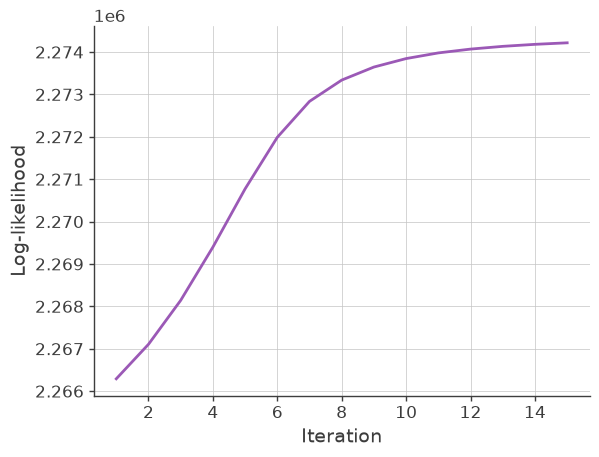

In [16]:
x, y = [], []

for result in image_deconvolution.results:
    x.append(result['iteration'])
    y.append(result["log-likelihood"])

plt.plot(x, y)
plt.grid()
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")

## 6. Optional localization diagnostics

The FastTSMap and MOCTSMap calculations inspect source localization. They are useful imaging diagnostics but are not inputs to the residual calculation in Sections 7 and 8.

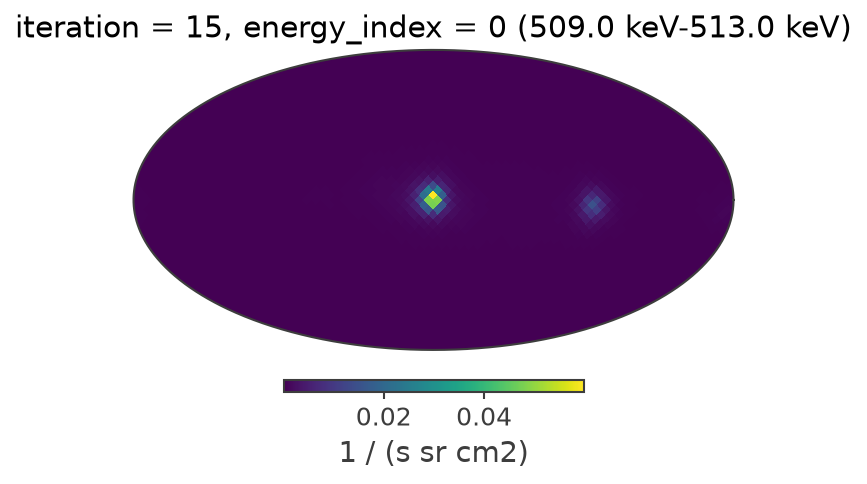

In [17]:
iteration = 14
plot_reconstructed_image(image_deconvolution.results[iteration])

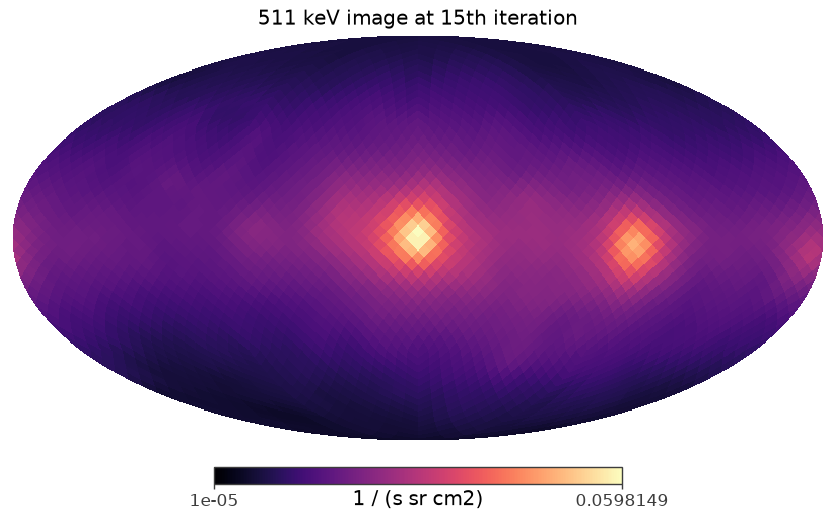

In [18]:
iteration_idx = 14

result = image_deconvolution.results[iteration_idx]

iteration = result[ 'iteration']
image = result['model']

data = image[:,0]
data[data <= 0 * data.unit] = 1e-12 * data.unit

hp.mollview(data, min = 1e-5, norm ='log', unit = str(data.unit), title = f'511 keV image at {iteration}th iteration', cmap = 'magma')

plt.show()

In [19]:
localization_spectrum = DiracDelta()

localization_spectrum.zero_point.value = 511.0
localization_spectrum.zero_point.unit = u.keV

localization_spectrum.value.value = 1.0e-3
localization_spectrum.value.unit = 1 / (u.cm**2 * u.s * u.keV)

In [20]:
FastTS_511keV = cp.FastTSMap(
    data = observed_event_hist,
    bkg_model= simulated_bg_counts_all,
    response_path=paths.data_ext_response511_path,
    cds_frame="galactic"
)

In [21]:
ts_results = FastTS_511keV.fit(
    nside = 16,
    spectrum= localization_spectrum,
    cpu_cores=10
)

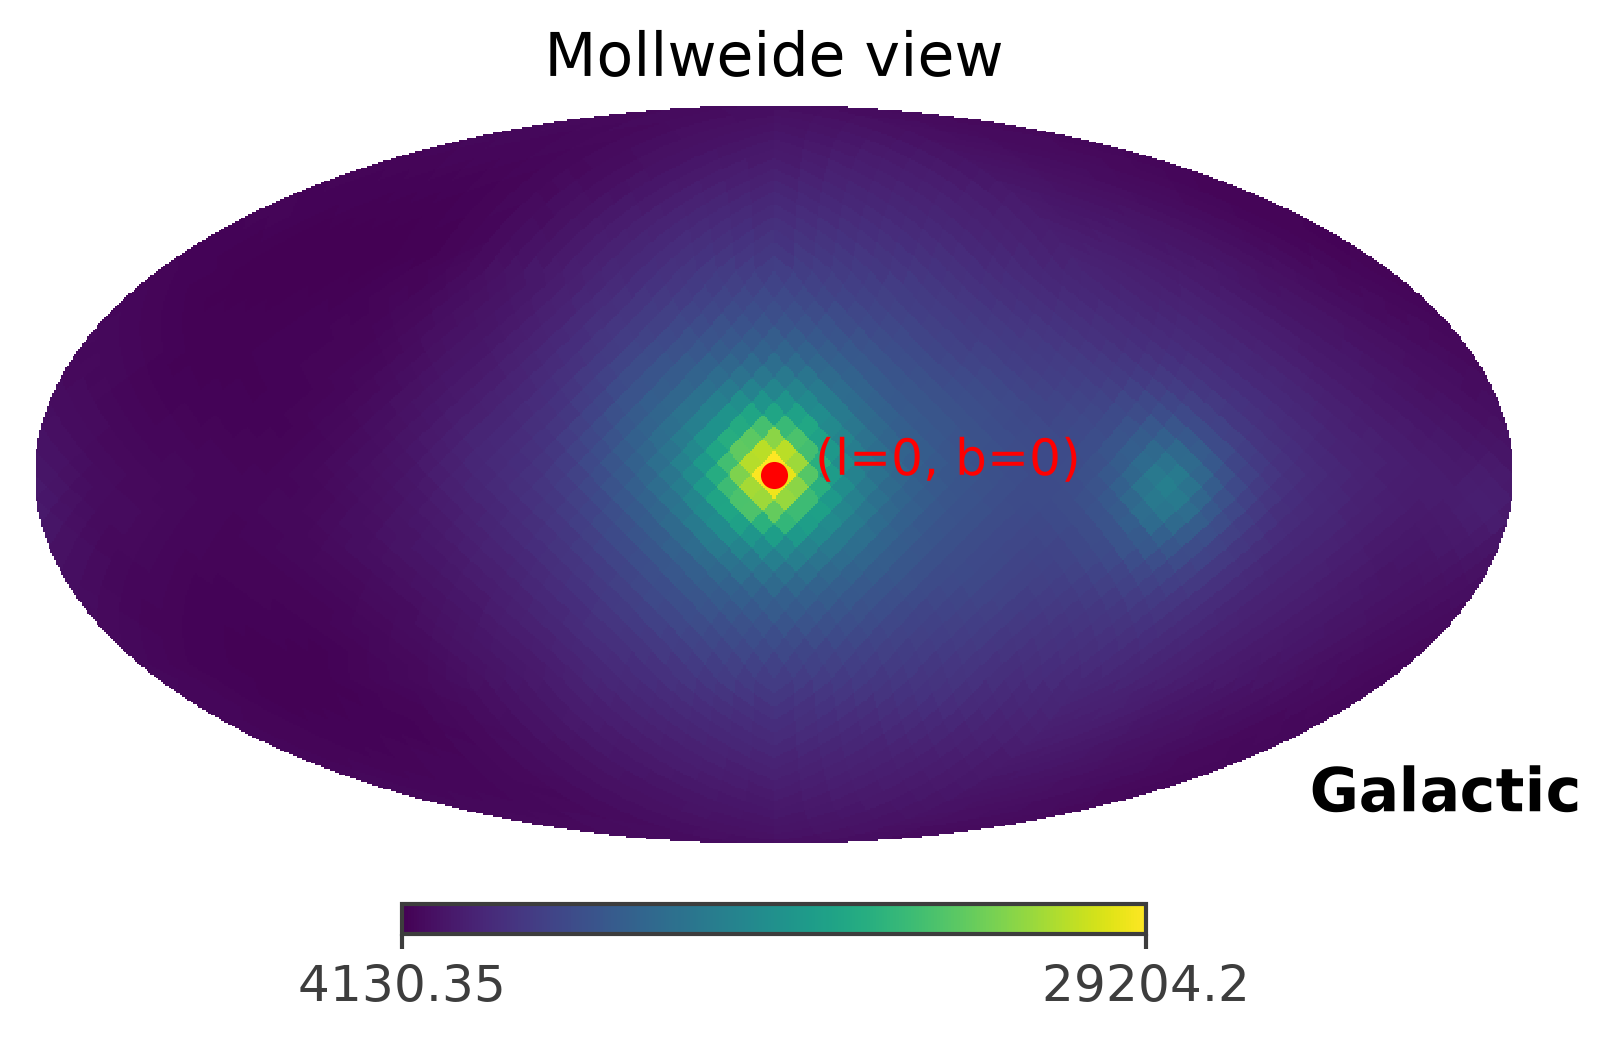

In [22]:
FastTS_511keV.plot_ts(
    ts_results, 
    save_plot = False)

In [23]:
# Configure an adaptive MOC TS map with the same data and response.
moc_fit_511keV = cp.MOCTSMap(
    data=observed_event_hist,
    bkg_model=simulated_bg_counts_all,
    response_path=paths.data_ext_response511_path,
    # No orientation is needed for the precomputed Galactic response.
    orientation=None,
    cds_frame="galactic",
)

In [24]:
# Fit the adaptive TS map up to the requested HEALPix resolution.
moc_ts, moc_uniq = moc_fit_511keV.fit(
    max_nside=16,
    spectrum=localization_spectrum,
)

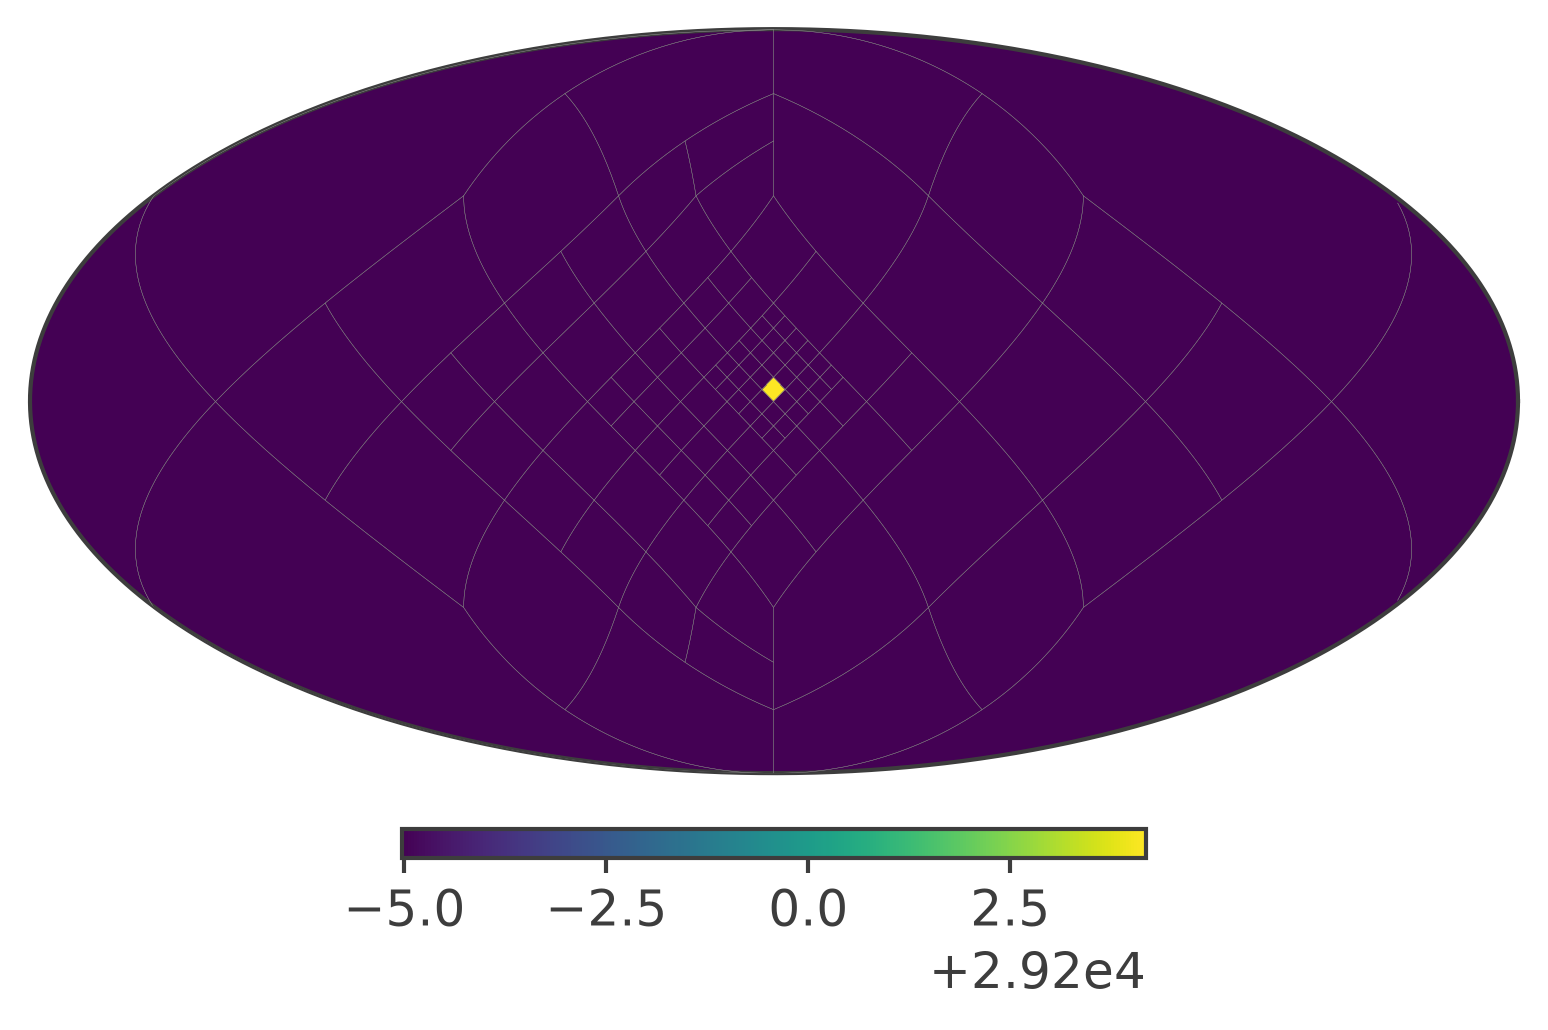

In [25]:
# Plot the raw TS values and the 99% containment region.
moc_fit_511keV.plot_ts(
    moc_ts,
    moc_uniq,
    dpi=300,
    containment=0.99,
)

## 7. Evaluate the fitted CDS expectation

The final reconstruction provides the fitted sky image and background normalization. Folding these fitted quantities through the same data interface produces the source, background, and total expected counts in exactly the observed `(Em, Phi, PsiChi)` bins.

In [26]:
# Read the fitted quantities from the final reconstruction iteration.
final_result = image_deconvolution.results[-1]
fitted_image = final_result["model"]
fitted_background_norm = final_result["background_normalization"]

# Fold the fitted sky and background models into the observed CDS bins.
source_expectation = data_interface.calc_source_expectation(fitted_image)
background_expectation = data_interface.calc_bkg_expectation(
    fitted_background_norm
)
total_expectation = data_interface.calc_expectation(
    fitted_image,
    fitted_background_norm,
)

### 7.1 Validate the observed and expected products

Residuals are meaningful only when observed and expected counts share identical bins. The total expectation must also equal the sum of its fitted source and background components.

In [27]:
# Require identical axes and shapes before comparing the histograms.
if observed_event_hist.axes != total_expectation.axes:
    raise ValueError("Observed and expected histograms have incompatible axes.")

if observed_event_hist.shape != total_expectation.shape:
    raise ValueError("Observed and expected histograms have incompatible shapes.")

component_sum = (
    source_expectation.contents + background_expectation.contents
)
if not np.allclose(total_expectation.contents, component_sum):
    raise ValueError("Total expectation does not match its component sum.")

print("Observed total:", observed_event_hist.contents.sum())
print("Source expectation total:", source_expectation.contents.sum())
print("Background expectation total:", background_expectation.contents.sum())
print("Total expectation:", total_expectation.contents.sum())
print("Background normalization:", fitted_background_norm)

Observed total: 1576953.0
Source expectation total: 193601.10441810387
Background expectation total: 1380440.5071258782
Total expectation: 1574041.6115439823
Background normalization: {'background': 1.003967684829928}


## 8. Residual analysis from in-memory histograms

`ResidualAnalysis` receives the integrated observation and the fitted total expectation directly. Unlike the file-based tutorial, this workflow does not call `Histogram.open()` because both histograms were produced in the current kernel.

In [28]:
# Associate the in-memory histograms explicitly with their analysis roles.
residual_analysis = ResidualAnalysis(
    observed=observed_event_hist,
    expected=total_expectation,
)

# Calculate one projected residual for direct numerical inspection.
phi_raw_residual = residual_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

print("Residual axes:", phi_raw_residual.axes.labels)
print("Residual shape:", phi_raw_residual.shape)
print("Mask report:", residual_analysis.mask_report)

Residual axes: ['Phi']
Residual shape: (60,)
Mask report: {'total_bins': 184320, 'valid_bins': np.int64(184320), 'excluded_bins': np.int64(0), 'observed_counts_excluded': np.float64(0.0), 'expected_floor': None, 'minimum_expected': <Quantity 1.e-12>, 'minimum_retained_expected': <Quantity 1.e-12>}


### 8.1 Projected residual diagnostics

The plotting interface reuses the same analysis object. Raw residuals show count differences, while Pearson residuals scale those differences by the square root of the fitted expectation.

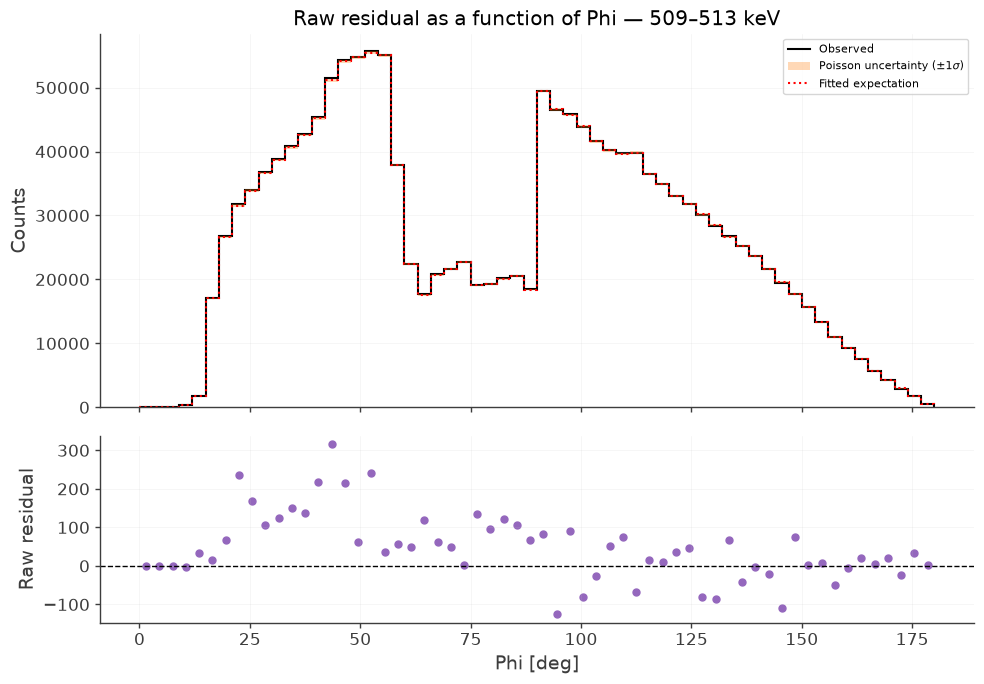


WARNING UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



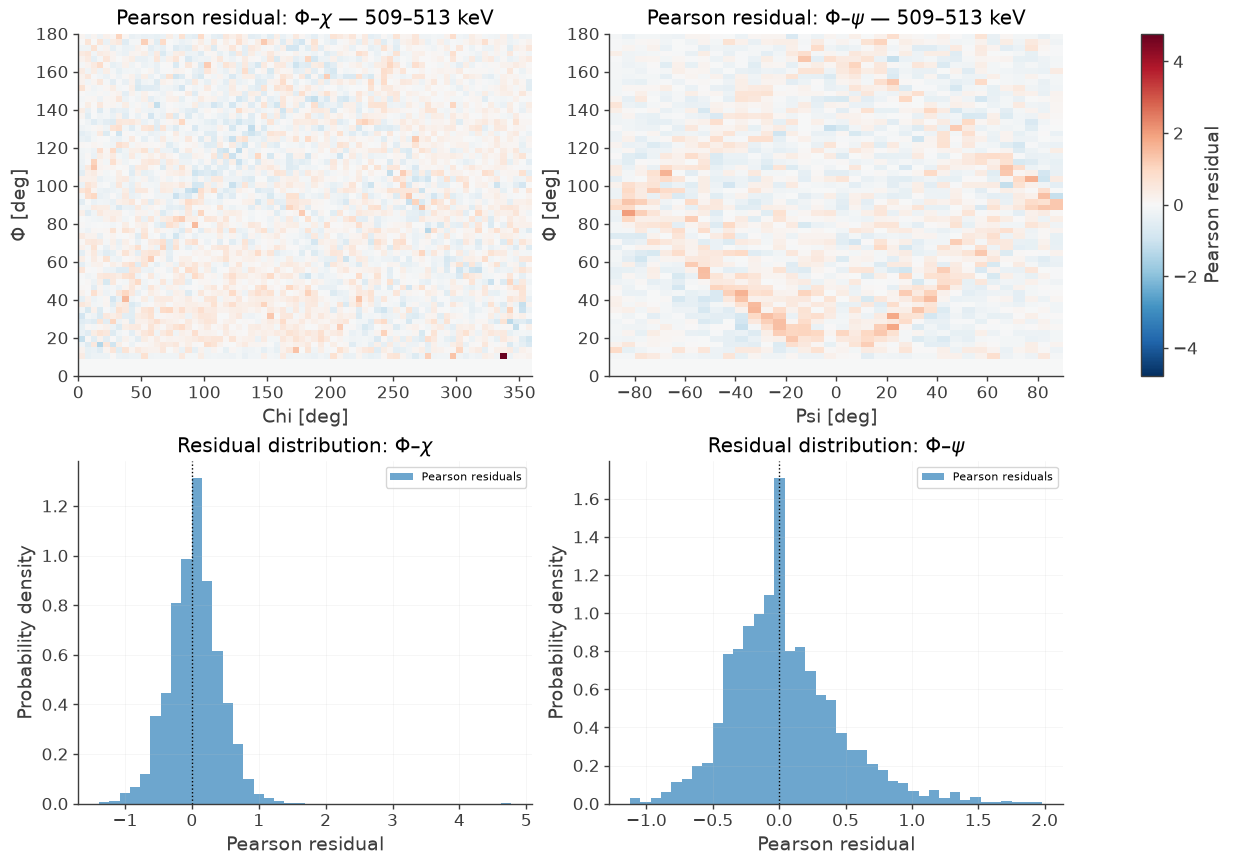

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,0.006158,-0.079596,0.445315,0.445357,-1.626413,17.35212,0.381402,0.212674,36558.590854,25525.814956


In [29]:
# Configure the plotting interface without Monte Carlo references.
residual_plotter = PlottingResiduals(residual_analysis)

# Compare observed and expected counts along the Phi projection.
phi_raw_figure = residual_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# Inspect the angular residual maps in expectation-scaled units.
angular_pearson_figure = residual_plotter.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

display(residual_analysis.statistics_table("pearson"))

In [34]:
# Build the paths to the original time-binned weekly observations.
weekly_time_paths = [
    paths.data_dir_out / f"dc4_week_{week}_511_binned.hdf5"
    for week in paths.weekly_paths
]

# Select one zero-based time-bin index from the combined weekly timeline.
time_bin_index = 13

# Construct a residual analysis for the selected temporal interval.
time_residual_analysis = ResidualAnalysis(
    observed=observed_event_hist,
    expected=total_expectation,
    time_residual=True,
    time_binned_observed=weekly_time_paths,
    time_bin_index=time_bin_index,
)

# Calculate the raw observed-minus-expected residual projected onto Phi.
time_phi_raw_residual = time_residual_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

print("Selected time-bin index:", time_residual_analysis.time_bin_index)
print("Time start:", time_residual_analysis.time_start)
print("Time stop:", time_residual_analysis.time_stop)
print("Residual axes:", time_phi_raw_residual.axes.labels)
print("Residual shape:", time_phi_raw_residual.shape)
print("Observed interval total:", time_residual_analysis.observed_hist.contents.sum())
print("Expected interval total:", time_residual_analysis.expected_hist.contents.sum())

Selected time-bin index: 13
Time start: 1835534092.734929 s
Time stop: 1835537692.1732924 s
Residual axes: ['Phi']
Residual shape: (60,)
Observed interval total: 597
Expected interval total: 597.0


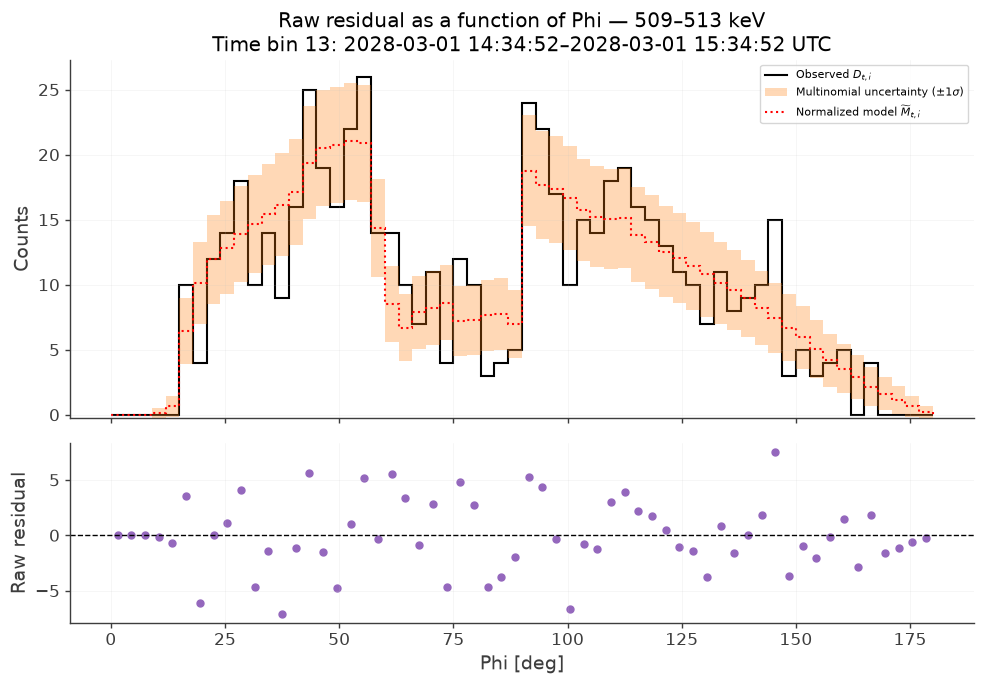


WARNING UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



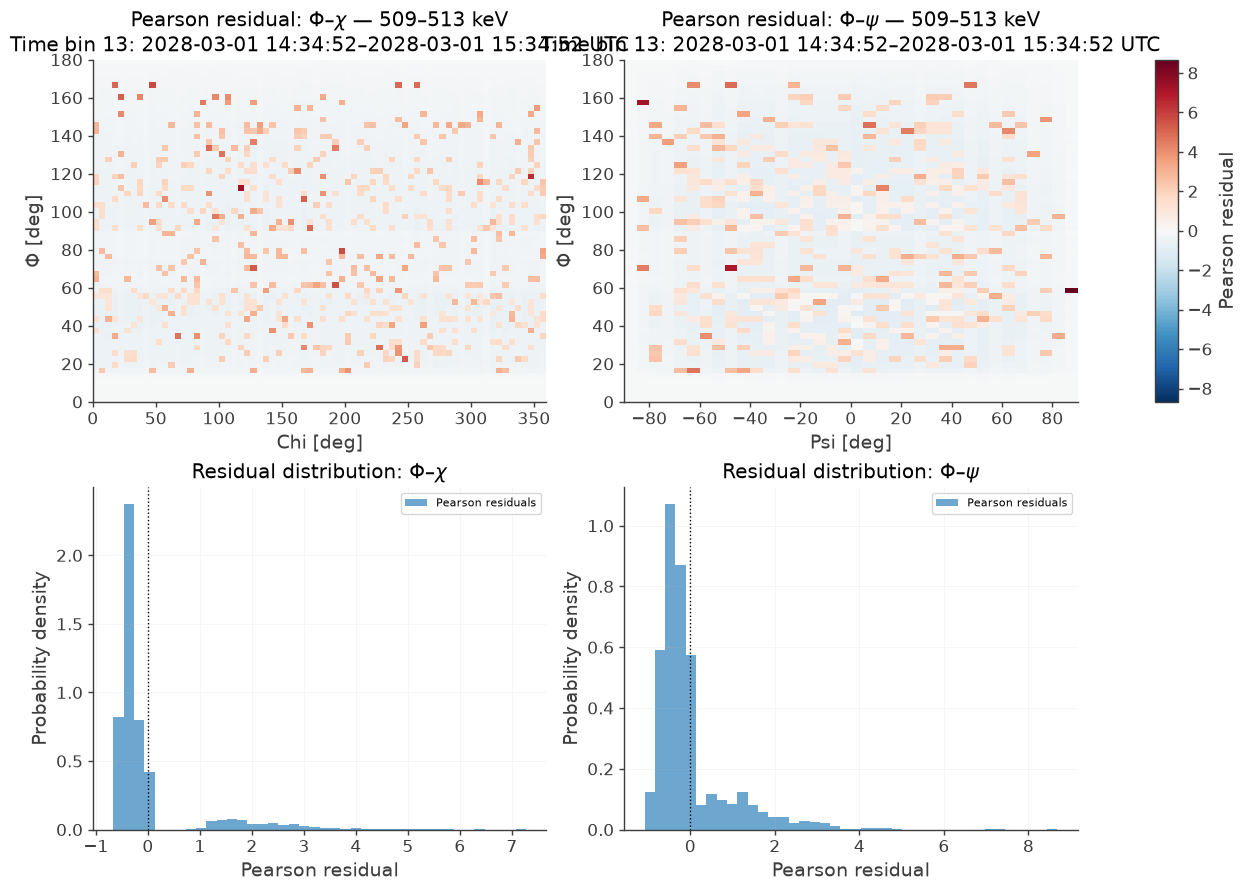

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,-0.000671,-0.054517,0.924643,0.924643,-0.116544,47.859025,0.323893,0.323893,157587.098076,6477.353306


In [35]:
# Create the plotting interface for the selected temporal interval.
time_residual_plotter = PlottingResiduals(
    time_residual_analysis
)

# Plot the observed-minus-expected residual projected onto Phi.
time_phi_raw_figure = time_residual_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# Inspect the angular residual maps in expectation-scaled units.
time_angular_pearson_figure = time_residual_plotter.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

display(time_residual_analysis.statistics_table("pearson"))